In [4]:
# %pip install pandas openpyxl

In [5]:
import json
import pandas as pd

with open('reference_data/vulnerability_contextualization_scanner_sample_updated.json', 'r') as f:
    json_data = json.load(f)

df_findings = pd.DataFrame(json_data['findings'])
nan_counts = df_findings.isna().sum()
print(nan_counts)

finding_id                        0
cve_id                            0
vulnerability_title               0
affected_product                  0
asset_group                       0
vulnerability_class               0
cvss_base_score                   0
cvss_severity                     0
exploitation_context              0
internet_facing_assets            0
exposure_classification           0
total_affected_assets             0
critical_assets                   0
high_criticality_assets           0
medium_criticality_assets         0
low_criticality_assets            0
patch_complexity                  0
estimated_remediation_effort      0
recommended_remediation           0
contextual_priority               0
data_status                       0
compensating_controls           180
dtype: int64


In [6]:
# Replace NaN with "No compensating controls"
df_findings['compensating_controls'] = df_findings['compensating_controls'].fillna('No compensating controls')

column_mapping = json_data['field_names']
df_findings_readable = df_findings.rename(columns=column_mapping)

print("Rows:", df_findings.shape[0])     # 300
print("Columns:", df_findings.shape[1])  # 22
df_findings_readable.head(3)

Rows: 300
Columns: 22


,Finding ID,CVE ID,Vulnerability title,Affected product,Asset group,Vulnerability class,CVSS base score,CVSS severity,Exploitation context,Internet-facing assets,...,Critical assets,High-criticality assets,Medium-criticality assets,Low-criticality assets,Patch complexity,Estimated remediation effort,Recommended remediation,Contextual priority,Data status,Compensating controls
0,VULN-0001,CVE-2021-44228,Apache Log4j2 JNDI RCE,Apache Log4j 2,Application / middleware,Remote code execution,10.0,Critical,Known exploited (validate current KEV status),0,...,5,4,3,47,Low,1â€“4 hours,"Patch, then rescan and confirm remediation",P2 - High,Synthetic scenario values; CVE/product metadat...,No compensating controls
1,VULN-0002,CVE-2021-45046,Apache Log4j2 follow-on vulnerability,Apache Log4j 2,Application / middleware,RCE / denial of service,9.0,Critical,No confirmed evidence in this sample,8,...,5,3,29,2,Low,1â€“4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,No compensating controls
2,VULN-0003,CVE-2021-45105,Apache Log4j2 denial of service,Apache Log4j 2,Application / middleware,Denial of service,7.5,High,No confirmed evidence in this sample,0,...,1,14,16,28,High,3â€“5 days,Upgrade to fixed supported release,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,No compensating controls


In [7]:

sheet_name = "Scanner Findings"
file_path = "reference_data/vulnerability_contextualization_scanner_sample_updated.xlsx"

df = pd.read_excel(file_path, sheet_name=sheet_name)
df

,Finding ID,CVE ID,Vulnerability title,Affected product,Asset group,Vulnerability class,CVSS base score,CVSS severity,Exploitation context,Internet-facing assets,...,Critical assets,High-criticality assets,Medium-criticality assets,Low-criticality assets,Patch complexity,Estimated remediation effort,Recommended remediation,Contextual priority,Data status,Compensating controls
0,VULN-0001,CVE-2021-44228,Apache Log4j2 JNDI RCE,Apache Log4j 2,Application / middleware,Remote code execution,10.0,Critical,Known exploited (validate current KEV status),0,...,5,4,3,47,Low,1–4 hours,"Patch, then rescan and confirm remediation",P2 - High,Synthetic scenario values; CVE/product metadat...,NaN
1,VULN-0002,CVE-2021-45046,Apache Log4j2 follow-on vulnerability,Apache Log4j 2,Application / middleware,RCE / denial of service,9.0,Critical,No confirmed evidence in this sample,8,...,5,3,29,2,Low,1–4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
2,VULN-0003,CVE-2021-45105,Apache Log4j2 denial of service,Apache Log4j 2,Application / middleware,Denial of service,7.5,High,No confirmed evidence in this sample,0,...,1,14,16,28,High,3–5 days,Upgrade to fixed supported release,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
3,VULN-0004,CVE-2021-26855,Microsoft Exchange SSRF (ProxyLogon),Exchange Server,Email / collaboration,SSRF,9.8,Critical,No confirmed evidence in this sample,12,...,5,14,23,17,Very High,1–3 weeks,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
4,VULN-0005,CVE-2021-26857,Microsoft Exchange insecure deserialization,Exchange Server,Email / collaboration,Remote code execution,9.8,Critical,No confirmed evidence in this sample,0,...,0,12,24,38,Low,1–4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,VULN-0296,CVE-2026-1731,BeyondTrust Remote Support / PRA OS command in...,BeyondTrust Remote Support,Network / remote access,Command injection,9.8,Critical,Known exploited (validate current KEV status),7,...,0,13,22,22,Low,1–4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
296,VULN-0297,CVE-2026-23760,SmarterMail authentication bypass via alternat...,SmarterTools SmarterMail,Email infrastructure,Authentication bypass,9.8,Critical,Known exploited (validate current KEV status),0,...,2,7,8,70,High,3–5 days,Apply vendor mitigation until patch window,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
297,VULN-0298,CVE-2026-41940,cPanel & WHM missing authentication for critic...,WebPros cPanel & WHM,Web application,Authentication bypass,9.8,Critical,Known exploited (validate current KEV status),18,...,4,7,29,39,Low,1–4 hours,Apply vendor mitigation until patch window,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,Service runs as non-root in a hardened contain...
298,VULN-0299,CVE-2026-9082,Drupal Core SQL injection (PostgreSQL),Drupal Core,Web application,SQL injection,9.8,Critical,Known exploited (validate current KEV status),0,...,0,10,25,0,Low,1–4 hours,Apply patch in maintenance window; validate se...,P2 - High,Synthetic scenario values; CVE/product metadat...,NaN


In [8]:
df.columns

Index(['Finding ID', 'CVE ID', 'Vulnerability title', 'Affected product',
       'Asset group', 'Vulnerability class', 'CVSS base score',
       'CVSS severity', 'Exploitation context', 'Internet-facing assets',
       'Exposure classification', 'Total affected assets', 'Critical assets',
       'High-criticality assets', 'Medium-criticality assets',
       'Low-criticality assets', 'Patch complexity',
       'Estimated remediation effort', 'Recommended remediation',
       'Contextual priority', 'Data status', 'Compensating controls'],
      dtype='str')

In [9]:
cve_col = "CVE ID" 

# 1. Check duplicate status
print("Total rows:", len(df))
print("Unique CVE count:", df[cve_col].nunique())
print("Missing CVE ID count:", df[cve_col].isna().sum())

# 2. Deduplicate on CVE ID (keep the first row only)
df_cve = df.drop_duplicates(subset=cve_col, keep="first").reset_index(drop=True)

print("Rows after deduplication:", len(df_cve))
df_cve.head(5)

Total rows: 300
Unique CVE count: 207
Missing CVE ID count: 0
Rows after deduplication: 207


,Finding ID,CVE ID,Vulnerability title,Affected product,Asset group,Vulnerability class,CVSS base score,CVSS severity,Exploitation context,Internet-facing assets,...,Critical assets,High-criticality assets,Medium-criticality assets,Low-criticality assets,Patch complexity,Estimated remediation effort,Recommended remediation,Contextual priority,Data status,Compensating controls
0,VULN-0001,CVE-2021-44228,Apache Log4j2 JNDI RCE,Apache Log4j 2,Application / middleware,Remote code execution,10.0,Critical,Known exploited (validate current KEV status),0,...,5,4,3,47,Low,1–4 hours,"Patch, then rescan and confirm remediation",P2 - High,Synthetic scenario values; CVE/product metadat...,NaN
1,VULN-0002,CVE-2021-45046,Apache Log4j2 follow-on vulnerability,Apache Log4j 2,Application / middleware,RCE / denial of service,9.0,Critical,No confirmed evidence in this sample,8,...,5,3,29,2,Low,1–4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
2,VULN-0003,CVE-2021-45105,Apache Log4j2 denial of service,Apache Log4j 2,Application / middleware,Denial of service,7.5,High,No confirmed evidence in this sample,0,...,1,14,16,28,High,3–5 days,Upgrade to fixed supported release,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
3,VULN-0004,CVE-2021-26855,Microsoft Exchange SSRF (ProxyLogon),Exchange Server,Email / collaboration,SSRF,9.8,Critical,No confirmed evidence in this sample,12,...,5,14,23,17,Very High,1–3 weeks,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN
4,VULN-0005,CVE-2021-26857,Microsoft Exchange insecure deserialization,Exchange Server,Email / collaboration,Remote code execution,9.8,Critical,No confirmed evidence in this sample,0,...,0,12,24,38,Low,1–4 hours,Apply vendor security update and verify version,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,NaN


In [10]:
# Count how many rows each CVE appears in, most frequent first
cve_counts = df[cve_col].value_counts()
cve_counts[cve_counts > 1]

CVE ID
CVE-2021-44228    2
CVE-2021-45046    2
CVE-2021-45105    2
CVE-2021-26855    2
CVE-2021-26857    2
                 ..
CVE-2024-30078    2
CVE-2024-38080    2
CVE-2024-21413    2
CVE-2024-30040    2
CVE-2024-38200    2
Name: count, Length: 93, dtype: int64

In [11]:
# Show all rows for CVEs that appear more than once, grouped together
dup_rows = df[df.duplicated(subset=cve_col, keep=False)].sort_values(cve_col)
dup_rows

,Finding ID,CVE ID,Vulnerability title,Affected product,Asset group,Vulnerability class,CVSS base score,CVSS severity,Exploitation context,Internet-facing assets,...,Critical assets,High-criticality assets,Medium-criticality assets,Low-criticality assets,Patch complexity,Estimated remediation effort,Recommended remediation,Contextual priority,Data status,Compensating controls
55,VULN-0056,CVE-2014-0160,OpenSSL Heartbleed,OpenSSL,Cryptographic library,Information disclosure,7.5,High,No confirmed evidence in this sample,0,...,0,10,34,19,Medium,1–2 days,Replace unsupported component or isolate service,P2 - High,Synthetic scenario values; CVE/product metadat...,Software-composition scanning flags vulnerable...
212,VULN-0213,CVE-2014-0160,OpenSSL Heartbleed,OpenSSL,Cryptographic library,Information disclosure,7.5,High,No confirmed evidence in this sample,0,...,5,2,6,42,Medium,1–2 days,"Patch, then rescan and confirm remediation",P3 - Planned,Synthetic scenario values; CVE/product metadat...,NaN
76,VULN-0077,CVE-2015-7547,glibc getaddrinfo buffer overflow,GNU glibc,Linux OS / library,Buffer overflow,8.4,High,No confirmed evidence in this sample,24,...,1,5,32,42,Very High,1–3 weeks,Apply patch in maintenance window; validate se...,P2 - High,Synthetic scenario values; CVE/product metadat...,NaN
233,VULN-0234,CVE-2015-7547,glibc getaddrinfo buffer overflow,GNU glibc,Linux OS / library,Buffer overflow,8.4,High,No confirmed evidence in this sample,13,...,3,4,19,28,Low,1–4 hours,Apply vendor mitigation until patch window,P2 - High,Synthetic scenario values; CVE/product metadat...,Services fronted by a TLS-terminating proxy / ...
60,VULN-0061,CVE-2016-5195,Linux kernel Dirty COW,Linux kernel,Linux OS,Privilege escalation,7.8,High,No confirmed evidence in this sample,19,...,5,10,16,51,Low,1–4 hours,Apply vendor mitigation until patch window,P2 - High,Synthetic scenario values; CVE/product metadat...,EDR / auditd rules alert on privilege-escalati...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,VULN-0226,CVE-2024-3094,XZ Utils supply-chain compromise,XZ Utils,Linux OS / library,Supply-chain compromise,10.0,Critical,No confirmed evidence in this sample,0,...,1,10,12,10,High,3–5 days,Replace unsupported component or isolate service,P1 - Urgent,Synthetic scenario values; CVE/product metadat...,Software-composition scanning flags vulnerable...
89,VULN-0090,CVE-2024-38080,Windows Hyper-V privilege escalation,Microsoft Windows,Virtualization,Privilege escalation,7.8,High,No confirmed evidence in this sample,0,...,1,11,9,47,High,3–5 days,Upgrade to fixed supported release,P2 - High,Synthetic scenario values; CVE/product metadat...,NaN
246,VULN-0247,CVE-2024-38080,Windows Hyper-V privilege escalation,Microsoft Windows,Virtualization,Privilege escalation,7.8,High,No confirmed evidence in this sample,0,...,1,2,32,10,High,3–5 days,Apply vendor mitigation until patch window,P3 - Planned,Synthetic scenario values; CVE/product metadat...,Host firewall blocks inbound SMB/RPC/RDP from ...
92,VULN-0093,CVE-2024-38200,Microsoft Office security feature bypass,Microsoft Office,Endpoint / productivity,Security feature bypass,7.5,High,No confirmed evidence in this sample,0,...,0,10,10,40,Medium,1–2 days,Replace unsupported component or isolate service,P3 - Planned,Synthetic scenario values; CVE/product metadat...,NaN


In [12]:
pd.set_option("display.max_colwidth", None)

unique_df = pd.DataFrame({
    "column": df.columns,
    "n_unique": [df[c].nunique(dropna=False) for c in df.columns],
    "unique_values": [df[c].unique().tolist() for c in df.columns],
})

unique_df

,column,n_unique,unique_values
0,Finding ID,300,"[VULN-0001, VULN-0002, VULN-0003, VULN-0004, VULN-0005, VULN-0006, VULN-0007, VULN-0008, VULN-0009, VULN-0010, VULN-0011, VULN-0012, VULN-0013, VULN-0014, VULN-0015, VULN-0016, VULN-0017, VULN-0018, VULN-0019, VULN-0020, VULN-0021, VULN-0022, VULN-0023, VULN-0024, VULN-0025, VULN-0026, VULN-0027, VULN-0028, VULN-0029, VULN-0030, VULN-0031, VULN-0032, VULN-0033, VULN-0034, VULN-0035, VULN-0036, VULN-0037, VULN-0038, VULN-0039, VULN-0040, VULN-0041, VULN-0042, VULN-0043, VULN-0044, VULN-0045, VULN-0046, VULN-0047, VULN-0048, VULN-0049, VULN-0050, VULN-0051, VULN-0052, VULN-0053, VULN-0054, VULN-0055, VULN-0056, VULN-0057, VULN-0058, VULN-0059, VULN-0060, VULN-0061, VULN-0062, VULN-0063, VULN-0064, VULN-0065, VULN-0066, VULN-0067, VULN-0068, VULN-0069, VULN-0070, VULN-0071, VULN-0072, VULN-0073, VULN-0074, VULN-0075, VULN-0076, VULN-0077, VULN-0078, VULN-0079, VULN-0080, VULN-0081, VULN-0082, VULN-0083, VULN-0084, VULN-0085, VULN-0086, VULN-0087, VULN-0088, VULN-0089, VULN-0090, VULN-0091, VULN-0092, VULN-0093, VULN-0094, VULN-0095, VULN-0096, VULN-0097, VULN-0098, VULN-0099, VULN-0100, ...]"
1,CVE ID,207,"[CVE-2021-44228, CVE-2021-45046, CVE-2021-45105, CVE-2021-26855, CVE-2021-26857, CVE-2021-26858, CVE-2021-27065, CVE-2021-34473, CVE-2021-34523, CVE-2021-31207, CVE-2021-34527, CVE-2021-1675, CVE-2020-1472, CVE-2020-0796, CVE-2019-0708, CVE-2017-0144, CVE-2022-30190, CVE-2023-23397, CVE-2023-36884, CVE-2022-41040, CVE-2022-41082, CVE-2023-34362, CVE-2023-35078, CVE-2023-3519, CVE-2023-4966, CVE-2022-27518, CVE-2019-19781, CVE-2021-22986, CVE-2020-5902, CVE-2023-20198, CVE-2023-20273, CVE-2022-1388, CVE-2022-22965, CVE-2022-22963, CVE-2021-21972, CVE-2021-22005, CVE-2022-22954, CVE-2023-20887, CVE-2021-21985, CVE-2022-26134, CVE-2023-22515, CVE-2023-22518, CVE-2022-36804, CVE-2021-22205, CVE-2023-7028, CVE-2020-14882, CVE-2021-2109, CVE-2023-21839, CVE-2017-5638, CVE-2018-11776, CVE-2021-41773, CVE-2021-42013, CVE-2023-25690, CVE-2023-44487, CVE-2019-17558, CVE-2014-0160, CVE-2022-0778, CVE-2022-1292, CVE-2023-0286, CVE-2024-0727, CVE-2016-5195, CVE-2022-0847, CVE-2021-4034, CVE-2021-3156, CVE-2022-0185, CVE-2023-32233, CVE-2023-4911, CVE-2024-1086, CVE-2024-3094, CVE-2019-5736, CVE-2021-30465, CVE-2020-8554, CVE-2021-25741, CVE-2019-10149, CVE-2019-15846, CVE-2020-28017, CVE-2015-7547, CVE-2018-1000001, CVE-2020-1350, CVE-2020-0601, CVE-2021-36934, CVE-2022-26925, CVE-2022-37969, CVE-2023-28252, CVE-2023-29336, CVE-2024-21412, CVE-2024-21338, CVE-2024-30051, CVE-2024-30078, CVE-2024-38080, CVE-2024-21413, CVE-2024-30040, CVE-2024-38200, CVE-2023-35311, CVE-2023-36025, CVE-2023-36874, CVE-2022-24521, CVE-2022-26904, CVE-2022-22047, CVE-2022-22005, ...]"
2,Vulnerability title,194,"[Apache Log4j2 JNDI RCE, Apache Log4j2 follow-on vulnerability, Apache Log4j2 denial of service, Microsoft Exchange SSRF (ProxyLogon), Microsoft Exchange insecure deserialization, Microsoft Exchange arbitrary file write, Microsoft Exchange ProxyShell, Microsoft Exchange privilege escalation, Microsoft Exchange security feature bypass, Windows PrintNightmare, Windows Print Spooler privilege escalation, Netlogon Zerologon, Windows SMBv3 SMBGhost, Remote Desktop Services BlueKeep, Windows SMBv1 EternalBlue, Microsoft Support Diagnostic Tool Follina, Microsoft Outlook privilege escalation, Windows / Office remote code execution, Exchange ProxyNotShell SSRF, Exchange ProxyNotShell RCE, MOVEit Transfer SQL injection, Ivanti EPMM authentication bypass, Citrix ADC / Gateway code injection, Citrix NetScaler information disclosure, Citrix ADC / Gateway code execution, Citrix ADC / Gateway path traversal, F5 BIG-IP iControl REST RCE, F5 BIG-IP TMUI RCE, Cisco IOS XE Web UI privilege escalation, Cisco IOS XE command injection, F5 BIG-IP authentication bypass, Spring Framework Spring4Shell, Spring Cloud Function SpEL injection, VMware vCenter Server RCE, VMware vCenter file upload RCE, VMware Workspace ONE Access RCE,

In [13]:
cisa_filtered_df = df[df['Exploitation context'].astype(str).str.lower().str.contains('known exploited')].copy()

print(f"Validate CISA KEV Items Count: {len(cisa_filtered_df)}")
cisa_filtered_df


Validate CISA KEV Items Count: 49


,Finding ID,CVE ID,Vulnerability title,Affected product,Asset group,Vulnerability class,CVSS base score,CVSS severity,Exploitation context,Internet-facing assets,...,Critical assets,High-criticality assets,Medium-criticality assets,Low-criticality assets,Patch complexity,Estimated remediation effort,Recommended remediation,Contextual priority,Data status,Compensating controls
0,VULN-0001,CVE-2021-44228,Apache Log4j2 JNDI RCE,Apache Log4j 2,Application / middleware,Remote code execution,10.0,Critical,Known exploited (validate current KEV status),0,...,5,4,3,47,Low,1–4 hours,"Patch, then rescan and confirm remediation",P2 - High,Synthetic scenario values; CVE/product metadata requires NVD validation,NaN
10,VULN-0011,CVE-2021-34527,Windows PrintNightmare,Microsoft Windows,Endpoint / server OS,Remote code execution,8.8,Critical,Known exploited (validate current KEV status),0,...,3,9,6,13,Medium,1–2 days,Upgrade to fixed supported release,P2 - High,Synthetic scenario values; CVE/product metadata requires NVD validation,Host firewall blocks inbound SMB/RPC/RDP from untrusted segments; EDR with exploit-protection / ASR rules in block mode
12,VULN-0013,CVE-2020-1472,Netlogon Zerologon,Windows Server,Identity infrastructure,Privilege escalation,10.0,Critical,Known exploited (validate current KEV status),0,...,5,9,29,57,Medium,1–2 days,Upgrade to fixed supported release,P3 - Planned,Synthetic scenario values; CVE/product metadata requires NVD validation,Server tiering: no direct inbound access from user VLANs; EDR with exploit-protection / ASR rules in block mode
14,VULN-0015,CVE-2019-0708,Remote Desktop Services BlueKeep,Microsoft Windows,Endpoint / server OS,Remote code execution,9.8,Critical,Known exploited (validate current KEV status),0,...,4,3,26,24,Medium,1–2 days,Replace unsupported component or isolate service,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,NaN
15,VULN-0016,CVE-2017-0144,Windows SMBv1 EternalBlue,Microsoft Windows,Endpoint / server OS,Remote code execution,8.1,Critical,Known exploited (validate current KEV status),0,...,0,4,19,49,Low,1–4 hours,Apply vendor mitigation until patch window,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,NaN
21,VULN-0022,CVE-2023-34362,MOVEit Transfer SQL injection,Progress MOVEit Transfer,File transfer / DMZ,SQL injection,9.8,Critical,Known exploited (validate current KEV status),0,...,1,7,21,25,Medium,1–2 days,Replace unsupported component or isolate service,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,NaN
22,VULN-0023,CVE-2023-35078,Ivanti EPMM authentication bypass,Ivanti EPMM,Mobile device management,Authentication bypass,10.0,Critical,Known exploited (validate current KEV status),3,...,3,4,17,14,Low,1–4 hours,Replace unsupported component or isolate service,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,NaN
23,VULN-0024,CVE-2023-3519,Citrix ADC / Gateway code injection,Citrix ADC / Gateway,Network / remote access,Remote code execution,9.8,Critical,Known exploited (validate current KEV status),3,...,0,3,5,14,Low,1–4 hours,Replace unsupported component or isolate service,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,MFA and source-IP allow-listing on admin access; geo-IP restrictions and rate limiting on exposed services
24,VULN-0025,CVE-2023-4966,Citrix NetScaler information disclosure,Citrix NetScaler,Network / remote access,Information disclosure,9.4,Critical,Known exploited (validate current KEV status),7,...,2,16,15,34,Very High,1–3 weeks,Apply vendor mitigation until patch window,P1 - Urgent,Synthetic scenario values; CVE/product metadata requires NVD validation,"Management plane isolated on an out-of-band VLAN, reachable only via bastion host; MFA and source-IP allow-listing on admin access"
26,VULN-0027,CVE-2019-19781,Citrix ADC / Gateway path traversal,Citrix ADC / Gateway,Network / remo

In [14]:
# %pip install matplotlib

In [15]:
# pip install ipykernel matplotlib

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

XLSX = "reference_data/vulnerability_contextualization_scanner_sample_updated.xlsx"
CSV = "reference_data/2026-10-20T03-47_export.csv"

# Original scanner findings (300 rows)
findings = pd.read_excel(XLSX, sheet_name="Scanner Findings")

# NVD validation export
nvd = pd.read_csv(CSV, encoding="utf-8-sig", index_col=0)

# Merge only the validation columns that the original sheet lacks
nvd_cols = ["Finding ID", "NVD score", "NVD severity", "Score Diff", "Score Match", "Status", "Issues", "NVD Link"]
df = findings.merge(nvd[nvd_cols], on="Finding ID", how="left", validate="1:1")
print(df.shape, "| unmatched:", df["Status"].isna().sum())

(300, 29) | unmatched: 0


In [17]:
# Keep rows that have an NVD score; flag mismatches beyond the 0.1 tolerance
scored = df.dropna(subset=["NVD score"]).copy()
scored["score_mismatch"] = scored["Score Diff"].abs() > 0.1

print(f"Rows with NVD score: {len(scored)} / {len(df)}")
print(f"Score mismatches: {scored['score_mismatch'].sum()} ({scored['score_mismatch'].mean():.1%})")
scored["Score Diff"].describe().round(2)

Rows with NVD score: 300 / 300
Score mismatches: 106 (35.3%)


count    300.00
mean      -0.19
std        0.95
min       -4.50
25%        0.00
50%        0.00
75%        0.00
max        4.50
Name: Score Diff, dtype: float64

In [18]:
# Keep rows that have an NVD score; flag mismatches beyond the 0.1 tolerance
scored = df.dropna(subset=["NVD score"]).copy()
scored["score_mismatch"] = scored["Score Diff"].abs() > 0.1

print(f"Rows with NVD score: {len(scored)} / {len(df)}")
print(f"Score mismatches: {scored['score_mismatch'].sum()} ({scored['score_mismatch'].mean():.1%})")
scored["Score Diff"].describe().round(2)

Rows with NVD score: 300 / 300
Score mismatches: 106 (35.3%)


count    300.00
mean      -0.19
std        0.95
min       -4.50
25%        0.00
50%        0.00
75%        0.00
max        4.50
Name: Score Diff, dtype: float64

In [19]:
# The export has no KEV column, so derive the status from the Issues text
issues = df["Issues"].fillna("")
df["kev_status"] = "Consistent"
df.loc[issues.str.contains("In CISA KEV"), "kev_status"] = "In KEV, sheet says no evidence"
df.loc[issues.str.contains("not in KEV"), "kev_status"] = "Sheet says exploited, not in KEV"

# Row level (findings) vs CVE level (deduplicated)
print(df["kev_status"].value_counts(), "\n")
kev_cve = df[df["kev_status"] != "Consistent"].drop_duplicates("CVE ID")
print(kev_cve["kev_status"].value_counts(), "\n")

# Products with the most KEV mismatches
kev_cve.groupby("Affected product").size().sort_values(ascending=False).head(10)

kev_status
In KEV, sheet says no evidence    162
Consistent                        138
Name: count, dtype: int64 

kev_status
In KEV, sheet says no evidence    102
Name: count, dtype: int64 



Affected product
Microsoft Windows         18
Exchange Server            9
VMware vCenter Server      5
Adobe ColdFusion           5
Linux kernel               4
Cisco ASA / FTD            3
Microsoft Outlook          3
SharePoint Server          3
Oracle WebLogic Server     3
Apache Struts              3
dtype: int64

In [20]:
nvd_cols = ["Finding ID", "NVD score", "NVD severity", "Score Diff", "Score Match",
            "NVD CVSS ver.", "NVD score source", "KEV", "Status", "Issues", "NVD Link"]
df = findings.merge(nvd[nvd_cols], on="Finding ID", how="left", validate="1:1")

scored = df.dropna(subset=["NVD score"]).copy()
scored["score_mismatch"] = scored["Score Diff"].abs() > 0.1
scored["is_primary"] = scored["NVD score source"].str.contains("Primary")

# Mismatch rate by CVSS version and by Primary/Secondary source
print(pd.crosstab(scored["NVD CVSS ver."], scored["score_mismatch"]))
print(pd.crosstab(scored["is_primary"], scored["score_mismatch"]))

# Mismatches where NVD itself (Primary) scored the CVE: the most reliable disagreements
scored[scored["score_mismatch"] & scored["is_primary"]].sort_values("Score Diff")[
    ["CVE ID", "Affected product", "CVSS base score", "NVD score", "Score Diff", "NVD CVSS ver."]]

score_mismatch  False  True 
NVD CVSS ver.               
3.0                 2      7
3.1               191     99
4.0                 1      0
score_mismatch  False  True 
is_primary                  
False              81     37
True              113     69


,CVE ID,Affected product,CVSS base score,NVD score,Score Diff,NVD CVSS ver.
150,CVE-2019-10108,Oracle WebLogic Server,9.8,5.4,-4.4,3.0
57,CVE-2022-1292,OpenSSL,9.8,7.3,-2.5,3.1
214,CVE-2022-1292,OpenSSL,9.8,7.3,-2.5,3.1
54,CVE-2019-17558,Apache Solr,9.8,7.5,-2.3,3.1
136,CVE-2023-29298,Adobe ColdFusion,9.8,7.5,-2.3,3.1
...,...,...,...,...,...,...
151,CVE-2023-0464,OpenSSL,5.3,7.5,2.2,3.1
50,CVE-2021-41773,Apache HTTP Server,7.5,9.8,2.3,3.1
207,CVE-2021-41773,Apache HTTP Server,7.5,9.8,2.3,3.1
126,CVE-2021-27905,MariaDB / MySQL,7.2,9.8,2.6,3.1


전체 행: 300
고유 값 수: 99


,count,percent
compensating_controls,,
No compensating controls,180,60.0
MFA and source-IP allow-listing on admin access; geo-IP restrictions and rate limiting on exposed services,4,1.3
Application allow-listing (WDAC) on servers; host firewall blocks inbound SMB/RPC/RDP from untrusted segments,4,1.3
Immutable backups and snapshot-integrity monitoring; management network isolated; access only via PAM bastion with MFA,3,1.0
Reverse proxy with SSO + MFA in front of the application; admin and management paths restricted to VPN / allow-listed source IPs,3,1.0
Admin and management paths restricted to VPN / allow-listed source IPs; WAF virtual-patching rule / managed signature set blocks known exploit patterns,3,1.0
EDR on mail servers with web-shell detection; email security gateway filters malicious messages and links,2,0.7
Host firewall blocks inbound SMB/RPC/RDP from untrusted segments; EDR with exploit-protection / ASR rules in block mode,2,0.7
Server tiering: no direct inbound access from user VLANs; EDR with exploit-protection / ASR rules in block mode,2,0.7


C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 54665 (\N{HANGUL SYLLABLE HAENG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 50948 (\N{HANGUL SYLLABLE WI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\eagle\AppData\Local\Temp\ipykernel_19580\1056738455.py:27: UserWarning: Glyph 54637 (\N{HANGUL SYLLABLE HANG}) missing f

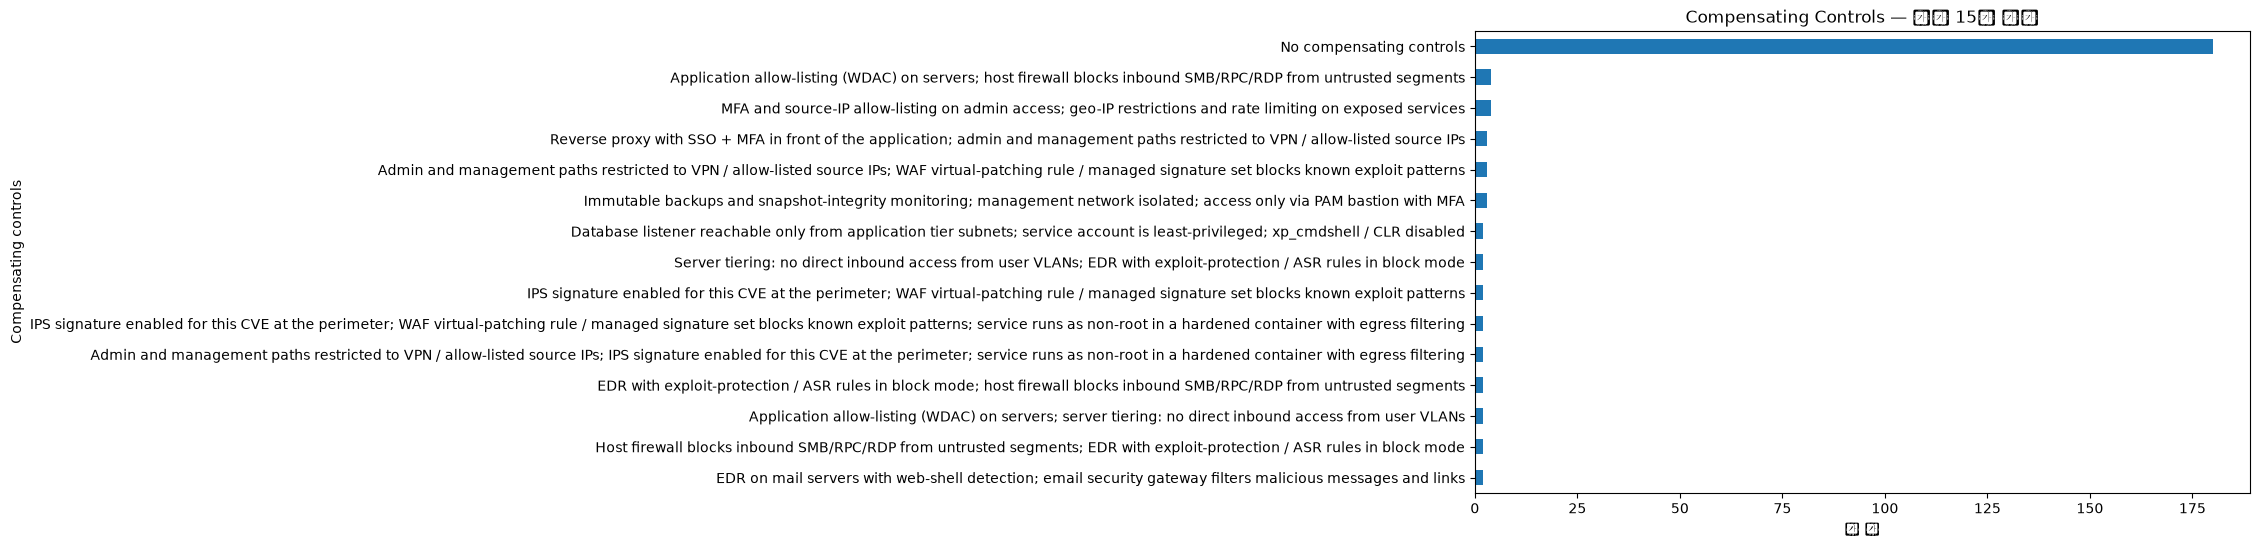

In [21]:
controls = (
    df_findings["compensating_controls"]
    .fillna("No compensating controls")
    .astype(str)
    .str.strip()
    .replace("", "No compensating controls")
)

counts = controls.value_counts()
summary = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(controls) * 100).round(1),
})

print(f"전체 행: {len(controls)}")
print(f"고유 값 수: {controls.nunique()}")
display(summary.head(15))

# 상위 항목 시각화
summary.head(15)["count"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Compensating Controls — 상위 15개 항목"
)
plt.xlabel("행 수")
plt.ylabel("Compensating controls")
plt.tight_layout()
plt.show()
